EXAMPLE CODE FOR CONTROLLING PICOSCOPE, LASER AND POWERMETER

In [1]:
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()

powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=100,
    bs_factor=1,
    wavelength=950
)


# ---------------------------------------------------------------------
# Utility functions
# ---------------------------------------------------------------------

def make_data_folder(base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')

    folder_path = os.path.join(
        base_directory,
        year,
        year_month,
        year_month_day
    )

    os.makedirs(folder_path, exist_ok=True)
    return folder_path


def format_for_filename(x):
    """Keep decimal points in filenames but remove spaces."""
    return str(x).strip().replace(" ", "")


def save_arrays(
        voltage_array,
        time_array,
        commanded_power_mW,
        measured_power_uW,
        iteration,
        gain_value,
        base_directory='D:/Data',
        save_time_once=True
):
    folder_path = make_data_folder(base_directory)
    timestamp = datetime.now().strftime('%H%M%S')

    laserp_str = f"{commanded_power_mW:.3g}"
    measp_str = f"{measured_power_uW:.3g}"
    gain_str = format_for_filename(gain_value)

    suffix = (
        f"laserp_{laserp_str}_mW"
        f"_measp_{measp_str}_uW"
        f"_iter{iteration:03d}"
        f"_gain_{gain_str}"
    )

    voltage_filename = f"pbec_{timestamp}_{suffix}_Voltage.txt"
    voltage_path = os.path.join(folder_path, voltage_filename)

    np.savetxt(voltage_path, voltage_array, fmt='%0.4f')

    time_path = None

    if save_time_once:
        time_filename = "pbec_Time.txt"
        time_path = os.path.join(folder_path, time_filename)

        if not os.path.exists(time_path):
            np.savetxt(time_path, time_array, fmt='%0.4f')

    return voltage_path, time_path

# ---------------------------------------------------------------------
# PicoScope acquisition
# ---------------------------------------------------------------------

def get_picoscope_data(
        channels=[0],
        analogue_offset=0,
        trig=0,
        trigsource=0,
        trigthresh=64,
        trigdir=2,
        trigdelay=0,
        trigms=1000,
        preTriggerSamples=2500,
        postTriggerSamples=2500,
        timebase=8,
        live_plot=False
):
    status = {}
    chandle = c_int16()
    serial = c_char_p()

    status["openunit"] = ps.ps6000OpenUnit(byref(chandle), serial)
    assert status["openunit"] == 0, (
        f"Failed to open PicoScope 6407, "
        f"error code: {status['openunit']}"
    )

    try:
        channel_mapping = {
            0: 'PS6000_CHANNEL_A',
            1: 'PS6000_CHANNEL_B',
            2: 'PS6000_CHANNEL_C',
            3: 'PS6000_CHANNEL_D'
        }

        buffers = {}
        chARange = ps.PS6000_RANGE['PS6000_100MV']

        maxSamples = preTriggerSamples + postTriggerSamples

        for ch in channels:
            if ch not in channel_mapping:
                raise ValueError("Invalid channel. Use 0, 1, 2, or 3.")

            channel = ps.PS6000_CHANNEL[channel_mapping[ch]]
            enabled = 1
            coupling_type = ps.PS6000_COUPLING['PS6000_DC_50R']
            bandwidth = ps.PS6000_BANDWIDTH_LIMITER['PS6000_BW_FULL']

            status[f"set_channel_{ch}"] = ps.ps6000SetChannel(
                chandle,
                channel,
                enabled,
                coupling_type,
                chARange,
                analogue_offset,
                bandwidth
            )
            assert_pico_ok(status[f"set_channel_{ch}"])

            buffers[ch] = {
                'max': (c_int16 * maxSamples)(),
                'min': (c_int16 * maxSamples)()
            }

            status[f"setDataBuffers_{ch}"] = ps.ps6000SetDataBuffers(
                chandle,
                channel,
                byref(buffers[ch]['max']),
                byref(buffers[ch]['min']),
                maxSamples,
                0
            )
            assert_pico_ok(status[f"setDataBuffers_{ch}"])

        status["trigger"] = ps.ps6000SetSimpleTrigger(
            chandle,
            trig,
            trigsource,
            trigthresh,
            trigdir,
            trigdelay,
            trigms
        )
        assert_pico_ok(status["trigger"])

        timeIntervalns = c_float()
        returnedMaxSamples = c_int32()

        status["getTimebase2"] = ps.ps6000GetTimebase2(
            chandle,
            timebase,
            maxSamples,
            byref(timeIntervalns),
            1,
            byref(returnedMaxSamples),
            0
        )
        assert_pico_ok(status["getTimebase2"])

        status["runBlock"] = ps.ps6000RunBlock(
            chandle,
            preTriggerSamples,
            postTriggerSamples,
            timebase,
            0,
            None,
            0,
            None,
            None
        )
        assert_pico_ok(status["runBlock"])

        ready = c_int16(0)

        while ready.value == 0:
            status["isReady"] = ps.ps6000IsReady(chandle, byref(ready))

        overflow = c_int16()
        cmaxSamples = c_int32(maxSamples)

        status["getValues"] = ps.ps6000GetValues(
            chandle,
            0,
            byref(cmaxSamples),
            1,
            0,
            0,
            byref(overflow)
        )
        assert_pico_ok(status["getValues"])

        maxADC = c_int16(32512)

        channel_data = {}

        for ch in channels:
            adc2mV_buffer = adc2mV(
                buffers[ch]['max'],
                chARange,
                maxADC
            )
            channel_data[ch] = np.array(adc2mV_buffer)

        time_array = np.linspace(
            0,
            (cmaxSamples.value - 1) * timeIntervalns.value,
            cmaxSamples.value
        )

        if live_plot:
            plt.figure(figsize=(6, 4))

            for ch in channels:
                plt.plot(
                    time_array,
                    channel_data[ch],
                    label=f"Channel {channel_mapping[ch]}"
                )

            plt.xlabel('Time (ns)')
            plt.ylabel('Voltage (mV)')
            plt.title("PicoScope capture")
            plt.legend()
            plt.grid()
            plt.show()

        status["stop"] = ps.ps6000Stop(chandle)
        assert_pico_ok(status["stop"])

    finally:
        ps.ps6000CloseUnit(chandle)

    return channel_data, time_array


# ---------------------------------------------------------------------
# Power meter thread
# ---------------------------------------------------------------------

def power_meter_worker(
        powermeter,
        stop_event,
        measured_power,
        measured_time,
        dt=0.1
):
    t0 = time.time()

    while not stop_event.is_set():
        try:
            reading_uW = 1e6 * powermeter.take_power_reading()
            measured_power.append(reading_uW)
            measured_time.append(time.time() - t0)

        except Exception:
            pass

        time.sleep(dt)


def acquire_scope_and_power(
        powermeter,
        scope_kwargs,
        power_meter_dt=0.1
):
    measured_power = []
    measured_time = []

    t0 = time.time()

    # One immediate reading before scope acquisition.
    # Failures are ignored to avoid cluttering the terminal.
    try:
        first_reading_uW = 1e6 * powermeter.take_power_reading()
        measured_power.append(first_reading_uW)
        measured_time.append(time.time() - t0)
    except Exception:
        pass

    stop_event = threading.Event()

    thread = threading.Thread(
        target=power_meter_worker,
        args=(
            powermeter,
            stop_event,
            measured_power,
            measured_time,
            power_meter_dt
        ),
        daemon=True
    )

    thread.start()

    try:
        channel_data, time_array = get_picoscope_data(**scope_kwargs)
    finally:
        stop_event.set()
        thread.join(timeout=2)

    # One final reading after scope acquisition.
    # Failures are ignored to avoid cluttering the terminal.
    try:
        final_reading_uW = 1e6 * powermeter.take_power_reading()
        measured_power.append(final_reading_uW)
        measured_time.append(time.time() - t0)
    except Exception:
        pass

    measured_power = np.array(measured_power)
    measured_time = np.array(measured_time)

    if len(measured_power) == 0:
        mean_power_uW = np.nan
        std_power_uW = np.nan
    else:
        mean_power_uW = np.mean(measured_power)
        std_power_uW = np.std(measured_power)

    return (
        channel_data,
        time_array,
        measured_time,
        measured_power,
        mean_power_uW,
        std_power_uW
    )


# ---------------------------------------------------------------------
# Full power scan
# ---------------------------------------------------------------------

def run_power_scan(
        power_list,
        laser,
        powermeter,
        n_iterations=1,
        base_directory='D:/Data',
        settle_time_s=1.0,
        power_meter_dt=0.1,
        channel_to_save=0,
        voltage_threshold_mV=80,
        initial_gain_value="NA",
        scope_kwargs=None
):
    """
    Power scan logic:
      1. Set laser power.
      2. Acquire scope trace and simultaneous power reading.
      3. Check saturation BEFORE saving.
      4. If saturated, ask for a new gain and reacquire the same iteration.
      5. Save only when the trace is not saturated.

    Saturated traces are deliberately discarded.
    """
    if scope_kwargs is None:
        scope_kwargs = dict(
            channels=[0],
            analogue_offset=0,
            trig=0,
            trigsource=0,
            trigthresh=64,
            trigdir=2,
            trigdelay=0,
            trigms=1000,
            preTriggerSamples=2500,
            postTriggerSamples=2500,
            timebase=8,
            live_plot=True
        )

    iteration = 0
    current_gain = initial_gain_value

    for power_W in power_list:
        commanded_power_mW = power_W * 1e3

        print("")
        print(f"Setting laser to {commanded_power_mW:.4f} mW")

        laser.set(power_W)
        time.sleep(settle_time_s)

        for _ in range(n_iterations):

            while True:
                print("")
                print(f"Iteration {iteration}")
                print(f"Current gain = {current_gain}")

                (
                    channel_data,
                    time_array,
                    power_time,
                    power_trace,
                    mean_power_uW,
                    std_power_uW
                ) = acquire_scope_and_power(
                    powermeter=powermeter,
                    scope_kwargs=scope_kwargs,
                    power_meter_dt=power_meter_dt
                )

                voltage_array = channel_data[channel_to_save]
                max_abs_voltage = np.max(np.abs(voltage_array))

                # ------------------------------------------------------
                # Check saturation BEFORE saving.
                # Saturated traces are discarded and reacquired.
                # ------------------------------------------------------
                if max_abs_voltage > voltage_threshold_mV:
                    print("")
                    print(
                        f"Signal exceeded ±{voltage_threshold_mV} mV "
                        f"(max |V| = {max_abs_voltage:.2f} mV)."
                    )
                    print("Please change gain.")

                    new_gain = input(
                        "Enter new gain value, then press Enter to reacquire this trace: "
                    )

                    if new_gain.strip() != "":
                        current_gain = new_gain.strip()

                    print(f"Reacquiring iteration {iteration} with gain = {current_gain}")
                    continue

                # ------------------------------------------------------
                # Save only if the trace is not saturated.
                # ------------------------------------------------------
                print(f"Measured power during trace: {mean_power_uW:.3g} uW")
                print(f"Max |V| = {max_abs_voltage:.2f} mV")

                voltage_path, time_path = save_arrays(
                    voltage_array=voltage_array,
                    time_array=time_array,
                    commanded_power_mW=commanded_power_mW,
                    measured_power_uW=mean_power_uW,
                    iteration=iteration,
                    gain_value=current_gain,
                    base_directory=base_directory,
                    save_time_once=True
                )

                print("Saved voltage:")
                print(voltage_path)

                if time_path is not None:
                    print("Time file:")
                    print(time_path)

                iteration += 1
                break

    print("")
    print("Power scan complete.")


TopticaBackendError: backend exception: SerialException("could not open port 'COM5': PermissionError(13, 'Access is denied.', None, 5)") ('could not open port 'COM5': PermissionError(13, 'Access is denied.', None, 5)')


Setting laser to 0.0000 mW

Iteration 0
Current gain = 70


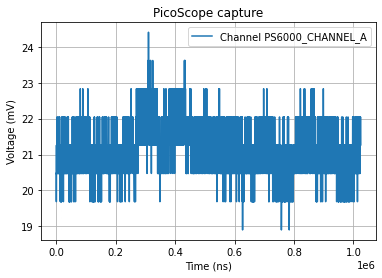

Measured power during trace: 1.43 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152547_laserp_0_mW_measp_1.43_uW_iter000_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 1
Current gain = 70


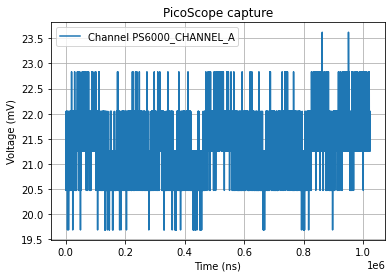

Measured power during trace: 1.43 uW
Max |V| = 23.62 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152557_laserp_0_mW_measp_1.43_uW_iter001_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 2
Current gain = 70


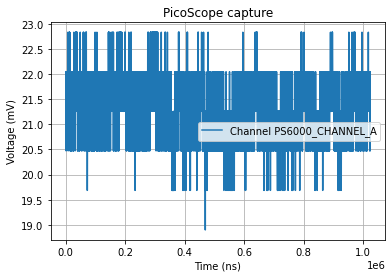

Measured power during trace: 1.43 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152608_laserp_0_mW_measp_1.43_uW_iter002_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 10.0000 mW

Iteration 3
Current gain = 70


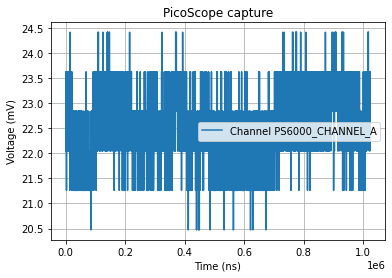

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152620_laserp_10_mW_measp_1.45_uW_iter003_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 4
Current gain = 70


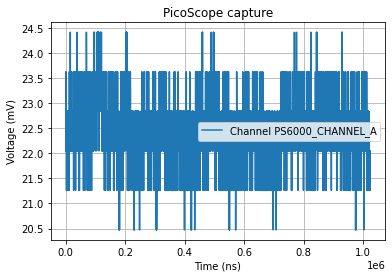

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152631_laserp_10_mW_measp_1.45_uW_iter004_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 5
Current gain = 70


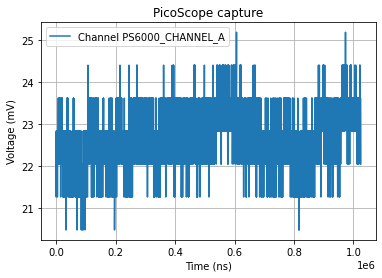

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152641_laserp_10_mW_measp_1.45_uW_iter005_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 10.5000 mW

Iteration 6
Current gain = 70


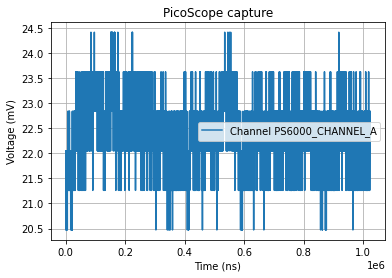

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152653_laserp_10.5_mW_measp_1.45_uW_iter006_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 7
Current gain = 70


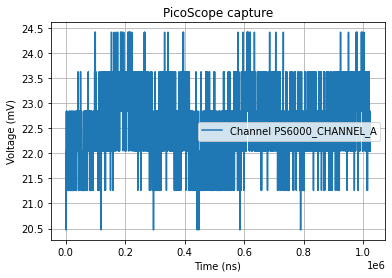

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152704_laserp_10.5_mW_measp_1.45_uW_iter007_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 8
Current gain = 70


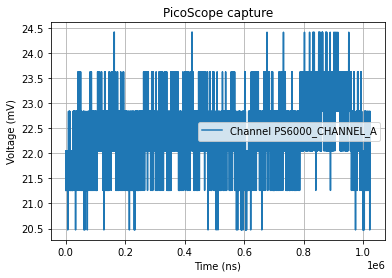

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152714_laserp_10.5_mW_measp_1.45_uW_iter008_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 11.0000 mW

Iteration 9
Current gain = 70


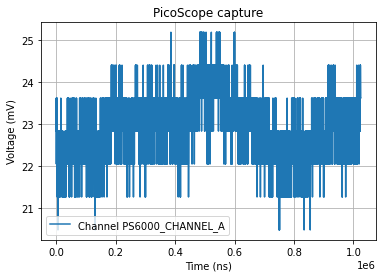

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152726_laserp_11_mW_measp_1.45_uW_iter009_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 10
Current gain = 70


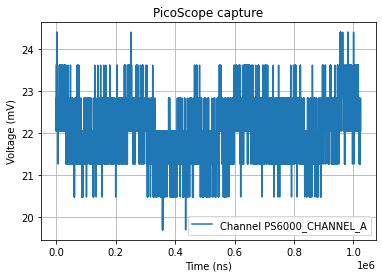

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152737_laserp_11_mW_measp_1.45_uW_iter010_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 11
Current gain = 70


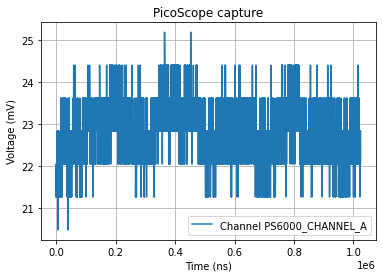

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152747_laserp_11_mW_measp_1.45_uW_iter011_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 11.5000 mW

Iteration 12
Current gain = 70


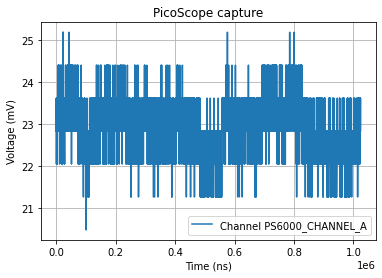

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152756_laserp_11.5_mW_measp_1.45_uW_iter012_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 13
Current gain = 70


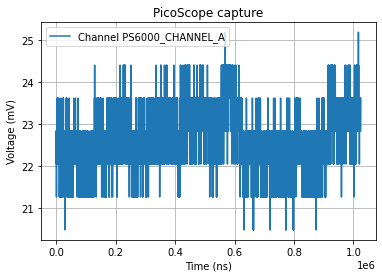

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152810_laserp_11.5_mW_measp_1.45_uW_iter013_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 14
Current gain = 70


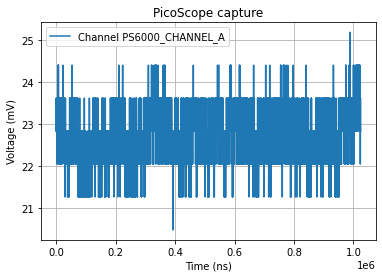

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152821_laserp_11.5_mW_measp_1.45_uW_iter014_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 12.0000 mW

Iteration 15
Current gain = 70


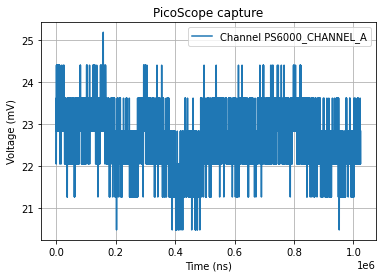

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152833_laserp_12_mW_measp_1.45_uW_iter015_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 16
Current gain = 70


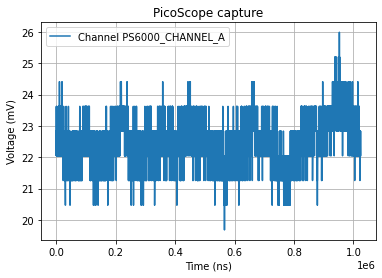

Measured power during trace: 1.45 uW
Max |V| = 25.98 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152843_laserp_12_mW_measp_1.45_uW_iter016_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 17
Current gain = 70


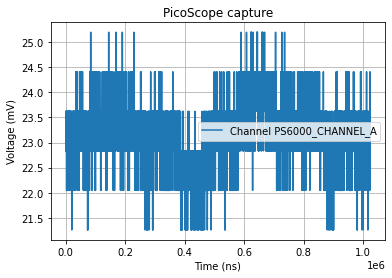

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152854_laserp_12_mW_measp_1.45_uW_iter017_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 12.5000 mW

Iteration 18
Current gain = 70


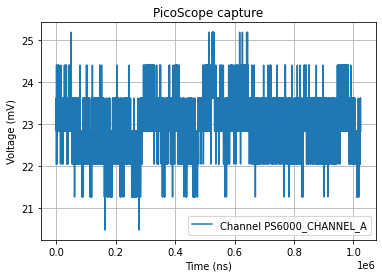

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152906_laserp_12.5_mW_measp_1.45_uW_iter018_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 19
Current gain = 70


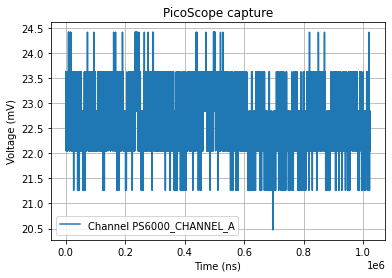

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152917_laserp_12.5_mW_measp_1.45_uW_iter019_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 20
Current gain = 70


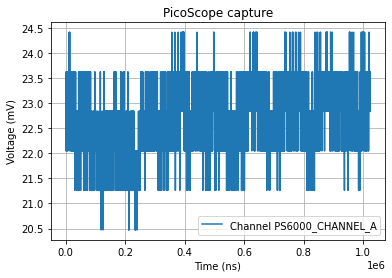

Measured power during trace: 1.45 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152924_laserp_12.5_mW_measp_1.45_uW_iter020_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 13.0000 mW

Iteration 21
Current gain = 70


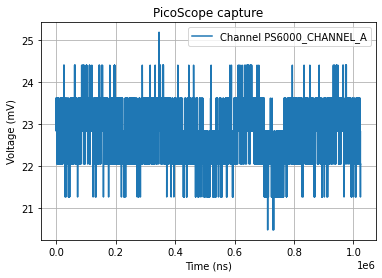

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152938_laserp_13_mW_measp_1.45_uW_iter021_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 22
Current gain = 70


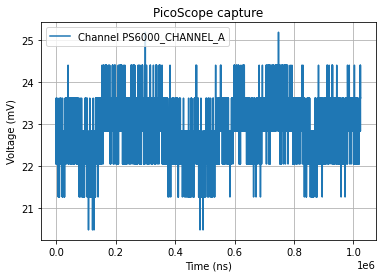

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152949_laserp_13_mW_measp_1.45_uW_iter022_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 23
Current gain = 70


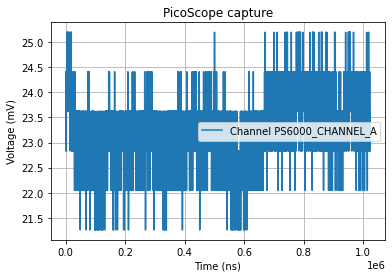

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_152959_laserp_13_mW_measp_1.45_uW_iter023_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 13.5000 mW

Iteration 24
Current gain = 70


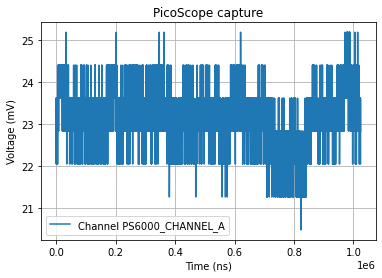

Measured power during trace: 1.45 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153011_laserp_13.5_mW_measp_1.45_uW_iter024_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 25
Current gain = 70


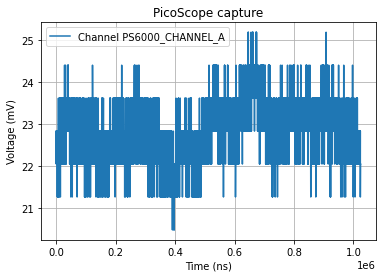

Measured power during trace: 1.46 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153022_laserp_13.5_mW_measp_1.46_uW_iter025_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 26
Current gain = 70


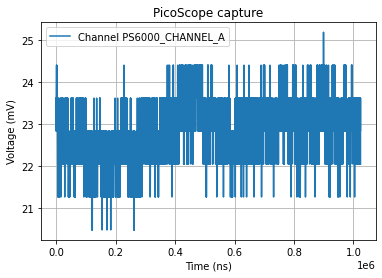

Measured power during trace: 1.46 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153032_laserp_13.5_mW_measp_1.46_uW_iter026_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 14.0000 mW

Iteration 27
Current gain = 70


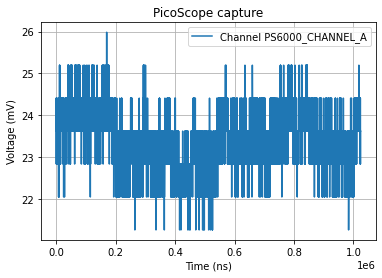

Measured power during trace: 1.46 uW
Max |V| = 25.98 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153044_laserp_14_mW_measp_1.46_uW_iter027_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 28
Current gain = 70


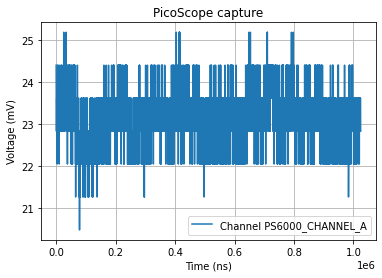

Measured power during trace: 1.46 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153055_laserp_14_mW_measp_1.46_uW_iter028_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 29
Current gain = 70


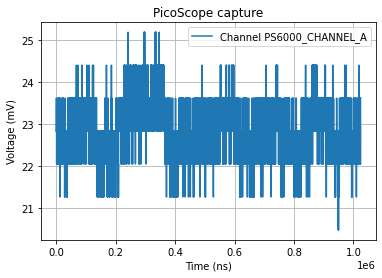

Measured power during trace: 1.46 uW
Max |V| = 25.20 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153106_laserp_14_mW_measp_1.46_uW_iter029_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 14.5000 mW

Iteration 30
Current gain = 70


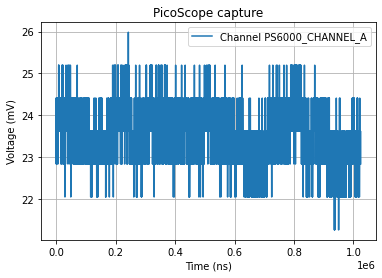

Measured power during trace: 1.46 uW
Max |V| = 25.98 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153118_laserp_14.5_mW_measp_1.46_uW_iter030_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 31
Current gain = 70


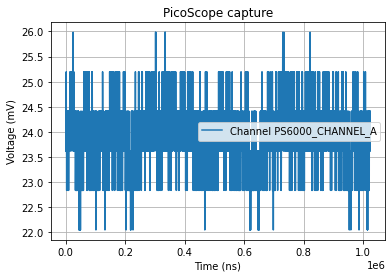

Measured power during trace: 1.46 uW
Max |V| = 25.98 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153128_laserp_14.5_mW_measp_1.46_uW_iter031_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 32
Current gain = 70


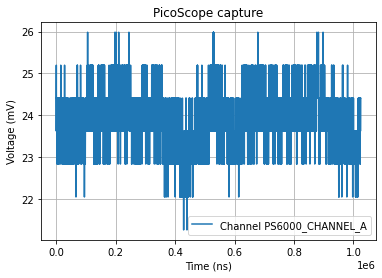

Measured power during trace: 1.46 uW
Max |V| = 25.98 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153139_laserp_14.5_mW_measp_1.46_uW_iter032_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 15.0000 mW

Iteration 33
Current gain = 70


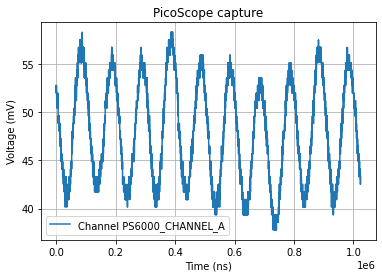

Measured power during trace: 1.49 uW
Max |V| = 58.27 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153148_laserp_15_mW_measp_1.49_uW_iter033_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 34
Current gain = 70


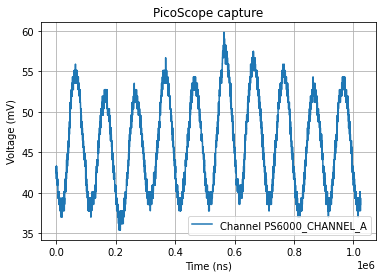

Measured power during trace: 1.48 uW
Max |V| = 59.84 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153202_laserp_15_mW_measp_1.48_uW_iter034_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 35
Current gain = 70


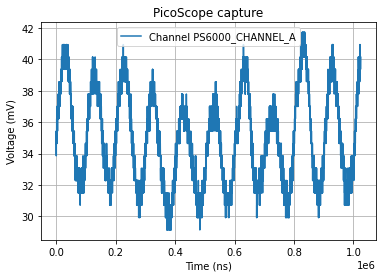

Measured power during trace: 1.48 uW
Max |V| = 41.73 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153212_laserp_15_mW_measp_1.48_uW_iter035_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 15.5000 mW

Iteration 36
Current gain = 70


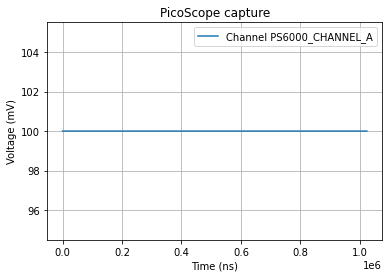


Signal exceeded ±90 mV (max |V| = 100.00 mV).
Please change gain.
Reacquiring iteration 36 with gain = 60

Iteration 36
Current gain = 60


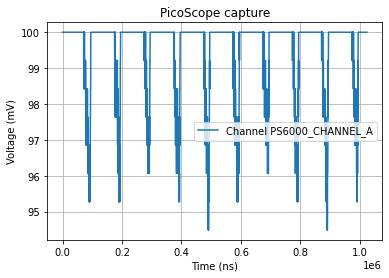


Signal exceeded ±90 mV (max |V| = 100.00 mV).
Please change gain.
Reacquiring iteration 36 with gain = 50

Iteration 36
Current gain = 50


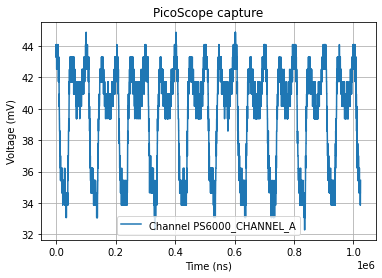

Measured power during trace: 1.81 uW
Max |V| = 44.88 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153307_laserp_15.5_mW_measp_1.81_uW_iter036_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 37
Current gain = 50


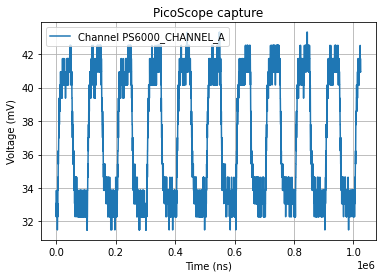

Measured power during trace: 1.77 uW
Max |V| = 43.31 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153318_laserp_15.5_mW_measp_1.77_uW_iter037_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 38
Current gain = 50


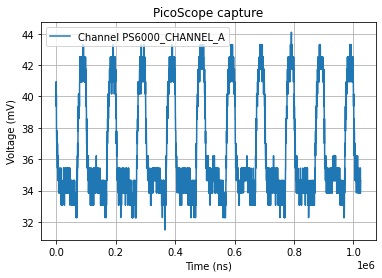

Measured power during trace: 1.75 uW
Max |V| = 44.09 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153329_laserp_15.5_mW_measp_1.75_uW_iter038_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 16.0000 mW

Iteration 39
Current gain = 50


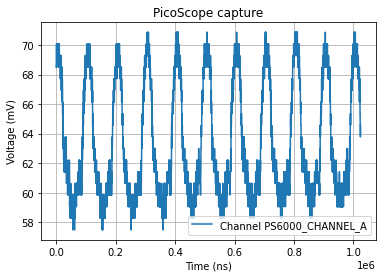

Measured power during trace: 2.03 uW
Max |V| = 70.87 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153341_laserp_16_mW_measp_2.03_uW_iter039_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 40
Current gain = 50


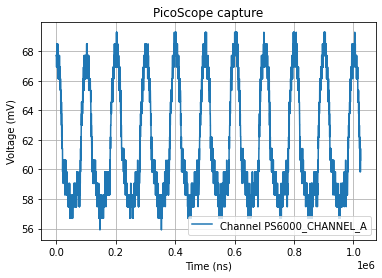

Measured power during trace: 2.04 uW
Max |V| = 69.29 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153351_laserp_16_mW_measp_2.04_uW_iter040_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 41
Current gain = 50


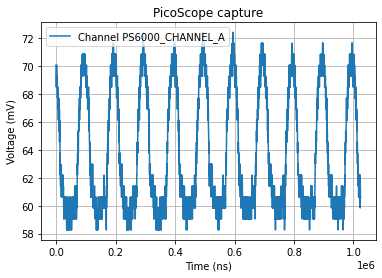

Measured power during trace: 2.05 uW
Max |V| = 72.44 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153402_laserp_16_mW_measp_2.05_uW_iter041_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 16.5000 mW

Iteration 42
Current gain = 50


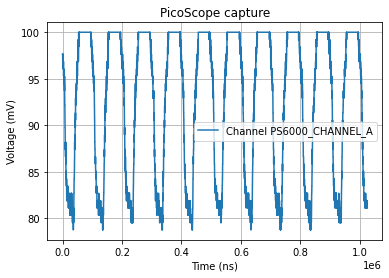


Signal exceeded ±90 mV (max |V| = 100.00 mV).
Please change gain.
Reacquiring iteration 42 with gain = 40

Iteration 42
Current gain = 40


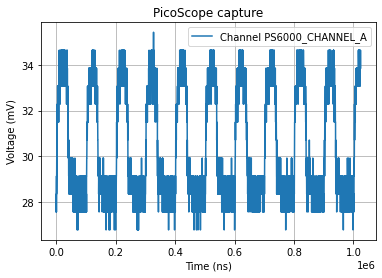

Measured power during trace: 2.26 uW
Max |V| = 35.43 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153607_laserp_16.5_mW_measp_2.26_uW_iter042_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 43
Current gain = 40


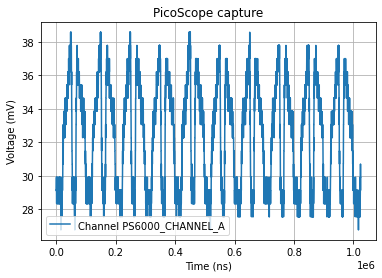

Measured power during trace: 2.34 uW
Max |V| = 38.58 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153618_laserp_16.5_mW_measp_2.34_uW_iter043_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 44
Current gain = 40


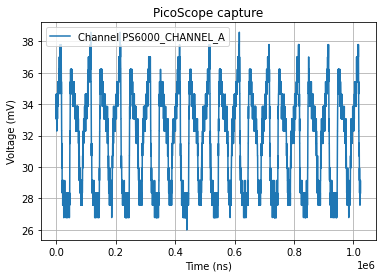

Measured power during trace: 2.3 uW
Max |V| = 38.58 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153629_laserp_16.5_mW_measp_2.3_uW_iter044_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 17.0000 mW

Iteration 45
Current gain = 40


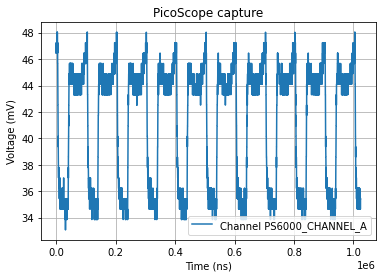

Measured power during trace: 2.61 uW
Max |V| = 48.03 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153640_laserp_17_mW_measp_2.61_uW_iter045_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 46
Current gain = 40


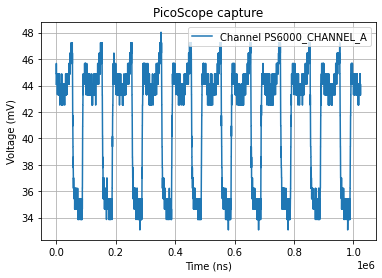

Measured power during trace: 2.62 uW
Max |V| = 48.03 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153651_laserp_17_mW_measp_2.62_uW_iter046_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 47
Current gain = 40


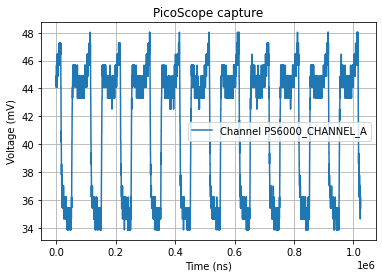

Measured power during trace: 2.6 uW
Max |V| = 48.03 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153702_laserp_17_mW_measp_2.6_uW_iter047_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 17.5000 mW

Iteration 48
Current gain = 40


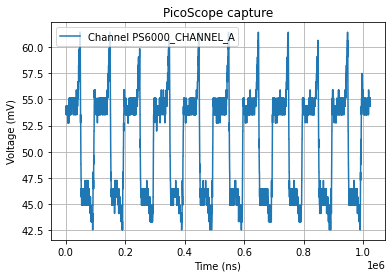

Measured power during trace: 2.87 uW
Max |V| = 61.42 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153714_laserp_17.5_mW_measp_2.87_uW_iter048_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 49
Current gain = 40


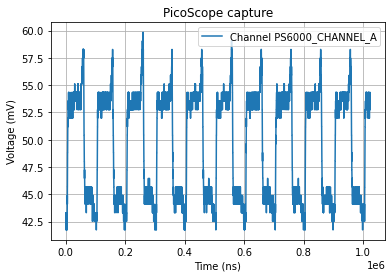

Measured power during trace: 2.9 uW
Max |V| = 59.84 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153725_laserp_17.5_mW_measp_2.9_uW_iter049_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 50
Current gain = 40


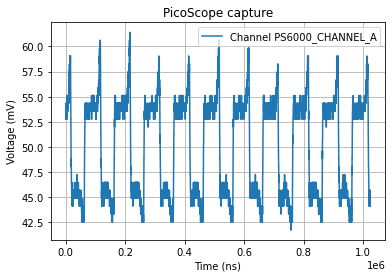

Measured power during trace: 2.89 uW
Max |V| = 61.42 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153735_laserp_17.5_mW_measp_2.89_uW_iter050_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 18.0000 mW

Iteration 51
Current gain = 40


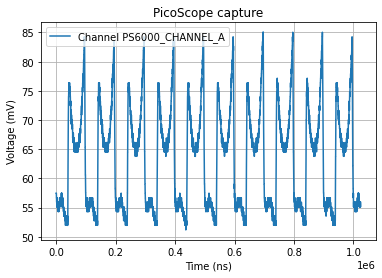

Measured power during trace: 3.31 uW
Max |V| = 85.04 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153747_laserp_18_mW_measp_3.31_uW_iter051_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 52
Current gain = 40


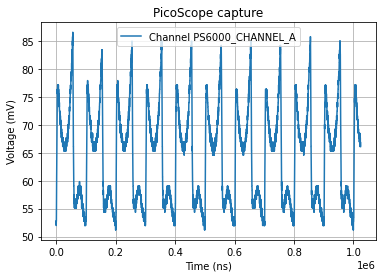

Measured power during trace: 3.37 uW
Max |V| = 86.61 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153755_laserp_18_mW_measp_3.37_uW_iter052_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 53
Current gain = 40


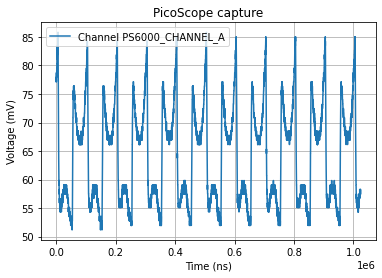

Measured power during trace: 3.36 uW
Max |V| = 85.83 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153809_laserp_18_mW_measp_3.36_uW_iter053_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 18.5000 mW

Iteration 54
Current gain = 40


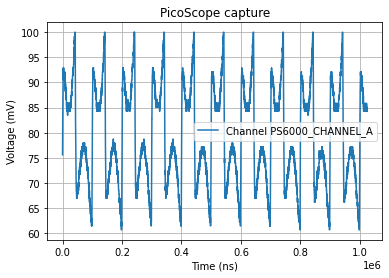


Signal exceeded ±90 mV (max |V| = 100.00 mV).
Please change gain.
Reacquiring iteration 54 with gain = 30

Iteration 54
Current gain = 30


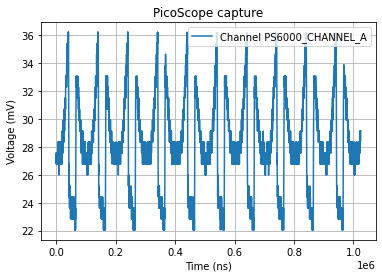

Measured power during trace: 3.96 uW
Max |V| = 36.22 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153849_laserp_18.5_mW_measp_3.96_uW_iter054_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 55
Current gain = 30


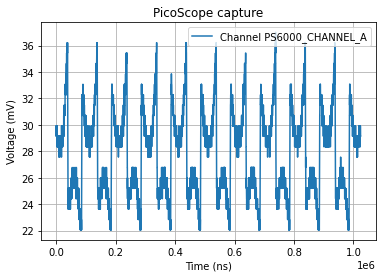

Measured power during trace: 3.82 uW
Max |V| = 37.01 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153859_laserp_18.5_mW_measp_3.82_uW_iter055_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 56
Current gain = 30


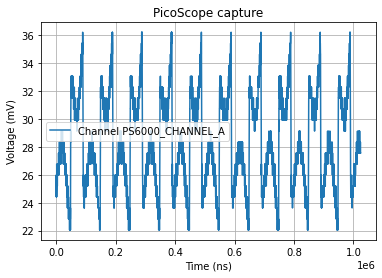

Measured power during trace: 3.89 uW
Max |V| = 36.22 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153910_laserp_18.5_mW_measp_3.89_uW_iter056_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 19.0000 mW

Iteration 57
Current gain = 30


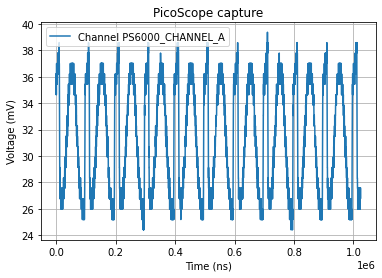

Measured power during trace: 4.23 uW
Max |V| = 39.37 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153922_laserp_19_mW_measp_4.23_uW_iter057_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 58
Current gain = 30


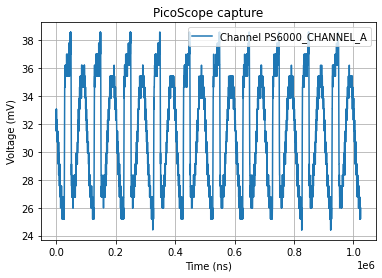

Measured power during trace: 4.23 uW
Max |V| = 38.58 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153933_laserp_19_mW_measp_4.23_uW_iter058_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 59
Current gain = 30


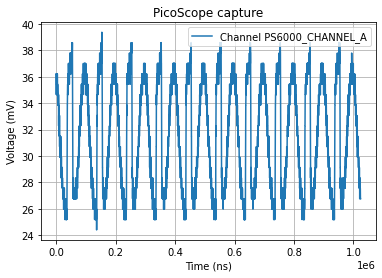

Measured power during trace: 4.25 uW
Max |V| = 39.37 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153940_laserp_19_mW_measp_4.25_uW_iter059_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Setting laser to 19.5000 mW

Iteration 60
Current gain = 30


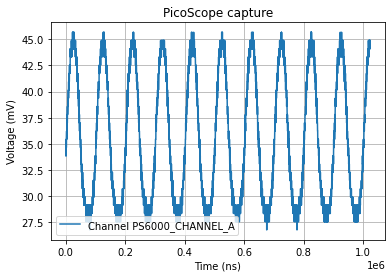

Measured power during trace: 4.61 uW
Max |V| = 45.67 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_153954_laserp_19.5_mW_measp_4.61_uW_iter060_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 61
Current gain = 30


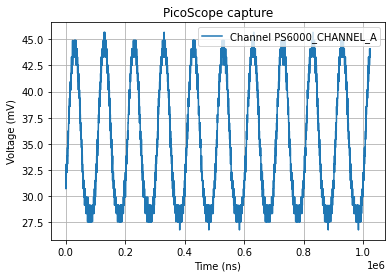

Measured power during trace: 4.59 uW
Max |V| = 45.67 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_154004_laserp_19.5_mW_measp_4.59_uW_iter061_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Iteration 62
Current gain = 30


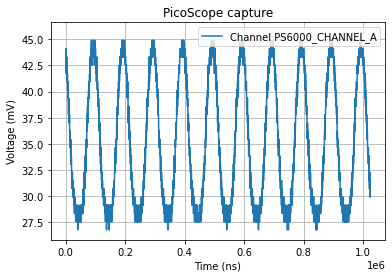

Measured power during trace: 4.57 uW
Max |V| = 45.67 mV
Saved voltage:
D:/Data\2026\202606\20260615\pbec_154015_laserp_19.5_mW_measp_4.57_uW_iter062_gain_30_Voltage.txt
Time file:
D:/Data\2026\202606\20260615\pbec_Time.txt

Power scan complete.


In [2]:

# ---------------------------------------------------------------------
# Example use
# ---------------------------------------------------------------------

power_list = np.append([0], np.arange(10, 20, 0.5) / 1000)
n_iter = 3
# Units are W here.
# 0.001 W = 1 mW
# 0.010 W = 10 mW

scope_settings = dict(
    channels=[0],
    analogue_offset=0,
    trig=0,
    trigsource=0,
    trigthresh=64,
    trigdir=2,
    trigdelay=0,
    trigms=1000,

    preTriggerSamples=0,
    postTriggerSamples=10000,

    timebase=20,

    live_plot=True
)

log_file = run_power_scan(
    power_list=power_list,
    n_iterations=n_iter,
    laser=laser,
    powermeter=powermeter,
    base_directory='D:/Data',
    settle_time_s=1.0,
    power_meter_dt=0.02,
    channel_to_save=0,
    voltage_threshold_mV=90,
    initial_gain_value='70',
    scope_kwargs=scope_settings
)